# L2 norms of the assigned fish: can the L2 tell correct from wrong assignments?

For every EOD, the L2 norm of the fish the rule assigns it to (the smallest of the candidate fish), three ways:
- **shape L2**: recorded main-phase pattern and model pattern each scaled to max |v| = 1 (no factors);
- **voltage L2, relative**: $\lVert r - a_f e_k\, \text{MODEL\_SIGN}\, u_f\rVert / \max|r|$, the voltage rule with fish factor $a_f$ and
  signed-electrode factors $e_k$ (electrode of each pair nearer to the fish);
- **voltage L2 (V)**: the same without dividing by $\max|r|$.

**4-fish, 00_12_52** (no ground truth): my model in the camera tank (L-barriers, interior 4 × water, N 150), median factors from
the 1000 best clean EODs per fish (`kaden_4fish_voltage_rule.py`). Per assigned fish and pooled; all EODs and good-mask EODs.

**2-/3-fish controls** (one emitter, the other fish silent, so every assignment is known to be correct or wrong): my model with
Kaden's masks in the camera tank of the controls, other fish with skin and an interior of **2** × water (the run closest to 4 that
exists, `with_Kaden_tracking/N150_tank_int2_none`). Voltage factors fitted the same way on each control's own true emitter (good-mask
EODs, 2 loudest pairs, medians): one fish factor (the emitter's, also used for the silent fish, which never emits) and 20 signed-
electrode factors; this is in-sample. Correct = the rule picks the true emitter.

Histograms on log-spaced bins; each group normalised to its own total (fraction of EODs), so the small group of wrong EODs is
visible; n per group in the legend. AUC: how well the L2 separates wrong from correct (0.5 = not at all, 1 = perfectly).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eod_assign import MODEL_SIGN
%matplotlib inline

OUT = 'results/eod_assign_4fish_kaden/l2_distributions'; os.makedirs(OUT, exist_ok=True)
LET, P = 'ABCD', 912
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E', 'all': '#2b2b2b'}
OK_COL, BAD_COL = '#1baf7a', '#eb6834'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
MEAS = {'shape': ('shape L2 (max |v| = 1)', np.logspace(-2, np.log10(3), 50)),
        'rel': ('voltage L2 / max|r|', np.logspace(-2, np.log10(5), 50)),
        'volt': ('voltage L2 (V)', np.logspace(-4, 0, 50))}

def auc(bad, good):
    '''P(L2 of a wrong EOD > L2 of a correct EOD), ties counted half.'''
    bad, good = np.sort(bad), np.sort(good)
    lo = np.searchsorted(good, bad, 'left'); hi = np.searchsorted(good, bad, 'right')
    return (lo + 0.5 * (hi - lo)).sum() / (len(bad) * len(good)) if len(bad) and len(good) else np.nan

def hist(ax, x, bins, color, label, filled=True):
    w = np.ones(len(x)) / max(len(x), 1)
    ax.hist(np.clip(x, bins[0], bins[-1]), bins=bins, weights=w, histtype='stepfilled' if filled else 'step',
            color=color, alpha=0.35 if filled else 1, lw=1.6, label=label)

## 4-fish recording 00_12_52 (no ground truth)

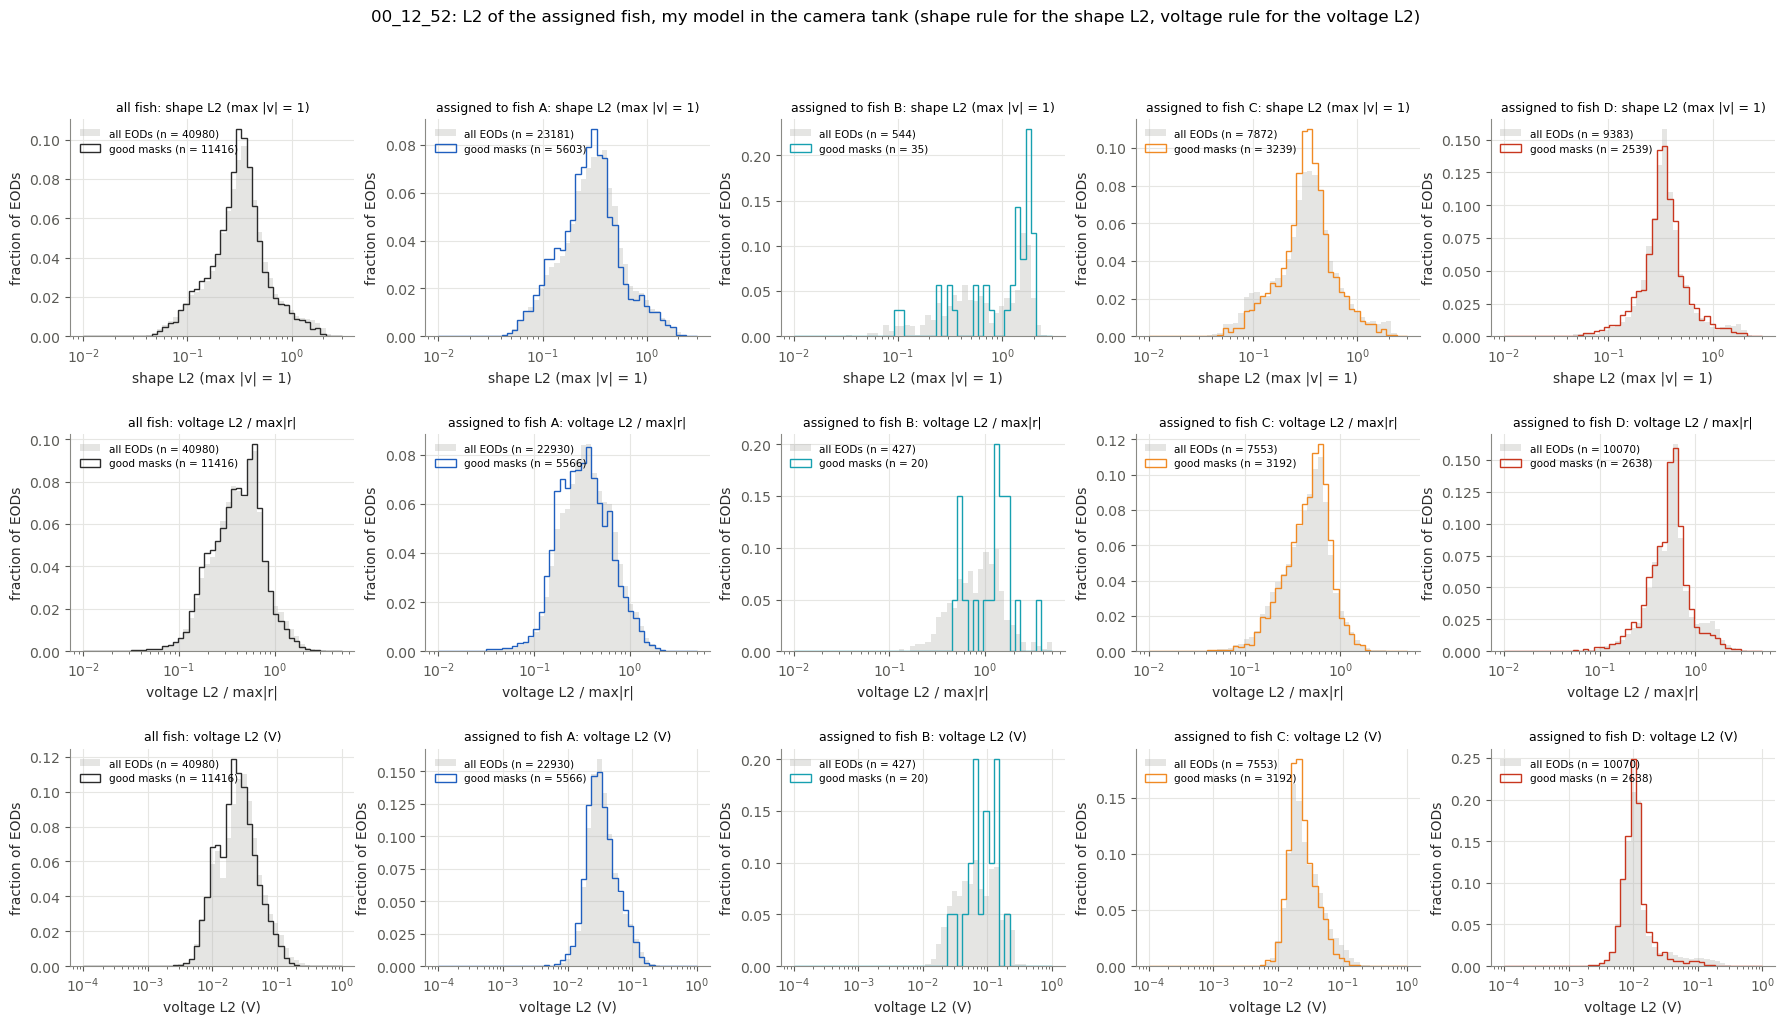

,measure,fish,n,median_all,median_good
0,shape L2 (max |v| = 1),all,40980,0.3249,0.3142
1,shape L2 (max |v| = 1),A,23181,0.3054,0.2846
2,shape L2 (max |v| = 1),B,544,0.6757,1.4257
3,shape L2 (max |v| = 1),C,7872,0.3321,0.3291
4,shape L2 (max |v| = 1),D,9383,0.3403,0.3371
5,voltage L2 / max|r|,all,40980,0.4290,0.4198
6,voltage L2 / max|r|,A,22930,0.3532,0.3242
7,voltage L2 / max|r|,B,427,0.8762,1.3449
8,voltage L2 / max|r|,C,7553,0.4751,0.4921
9,voltage L2 / max|r|,D,10070,0.5594,0.5489


In [2]:
d = pd.read_csv('results/eod_assign_4fish_kaden/00_12_52/voltage_rule_N150_tank_barriers_int4.csv', keep_default_na=False)
d = d[d.pick_voltage != ''].reset_index(drop=True)
pv = d.pick_voltage.map(LET.index).to_numpy(); ps = d.pick_shape.map(LET.index).to_numpy(); ii = np.arange(len(d))
DV = d[[f'd_volt_{f}' for f in LET]].replace('', np.nan).astype(float).to_numpy(); DS = d[[f'd_shape_{f}' for f in LET]].replace('', np.nan).astype(float).to_numpy()
X = {'shape': (DS[ii, ps], d.pick_shape.to_numpy()), 'rel': (DV[ii, pv] / d.r_max.to_numpy(), d.pick_voltage.to_numpy()),
     'volt': (DV[ii, pv], d.pick_voltage.to_numpy())}
good = d.good_masks.astype(str).str.lower().eq('true').to_numpy()
fig, axs = plt.subplots(3, 5, figsize=(22, 11), gridspec_kw=dict(hspace=0.45, wspace=0.25))
rows = []
for r_, (m, (xlab, bins)) in enumerate(MEAS.items()):
    x, pk = X[m]
    for c_, f in enumerate(['all'] + list(LET)):
        ax = axs[r_, c_]; k = np.ones(len(d), bool) if f == 'all' else pk == f
        hist(ax, x[k], bins, '#b5b5b0', f'all EODs (n = {k.sum()})')
        hist(ax, x[k & good], bins, FISH_COL[f], f'good masks (n = {(k & good).sum()})', filled=False)
        ax.set(xscale='log', ylim=(0, None), xlabel=xlab, ylabel='fraction of EODs')
        ax.set_title(f'{"all fish" if f == "all" else "assigned to fish " + f}: {xlab}', fontsize=9)
        ax.legend(frameon=False, fontsize=7.5, loc='upper left')
        rows.append(dict(measure=xlab, fish=f, n=int(k.sum()), median_all=np.median(x[k]) if k.any() else np.nan,
                         median_good=np.median(x[k & good]) if (k & good).any() else np.nan))
fig.suptitle('00_12_52: L2 of the assigned fish, my model in the camera tank (shape rule for the shape L2, voltage rule for the voltage L2)', fontsize=12)
fig.savefig(f'{OUT}/l2_00_12_52.png', dpi=100, bbox_inches='tight'); plt.show()
display(pd.DataFrame(rows).round(4))

## 2-/3-fish controls: correct vs wrong

2-fish: fish factor 0.4166; 21018 emitter ratios


3-fish: fish factor 0.8972; 16301 emitter ratios


,control,measure,subset,n,accuracy,n_wrong,median_correct,median_wrong,AUC_wrong_vs_correct
0,2-fish,shape L2 (max |v| = 1),all EODs,18801,97.952,385,0.286,1.023,0.804
1,2-fish,shape L2 (max |v| = 1),good masks,10804,98.880,121,0.275,1.486,0.913
2,2-fish,voltage L2 / max|r|,all EODs,18801,98.287,322,0.359,1.049,0.865
3,2-fish,voltage L2 / max|r|,good masks,10804,99.630,40,0.355,0.899,0.847
4,2-fish,voltage L2 (V),all EODs,18801,98.287,322,0.058,0.137,0.744
5,2-fish,voltage L2 (V),good masks,10804,99.630,40,0.059,0.094,0.700
6,3-fish,shape L2 (max |v| = 1),all EODs,19796,85.841,2803,0.402,1.463,0.938
7,3-fish,shape L2 (max |v| = 1),good masks,8250,98.861,94,0.394,1.036,0.910
8,3-fish,voltage L2 / max|r|,all EODs,19796,86.517,2669,0.422,1.341,0.937
9,3-fish,voltage L2 / max|r|,good masks,8250,99.624,31,0.405,1.075,0.881


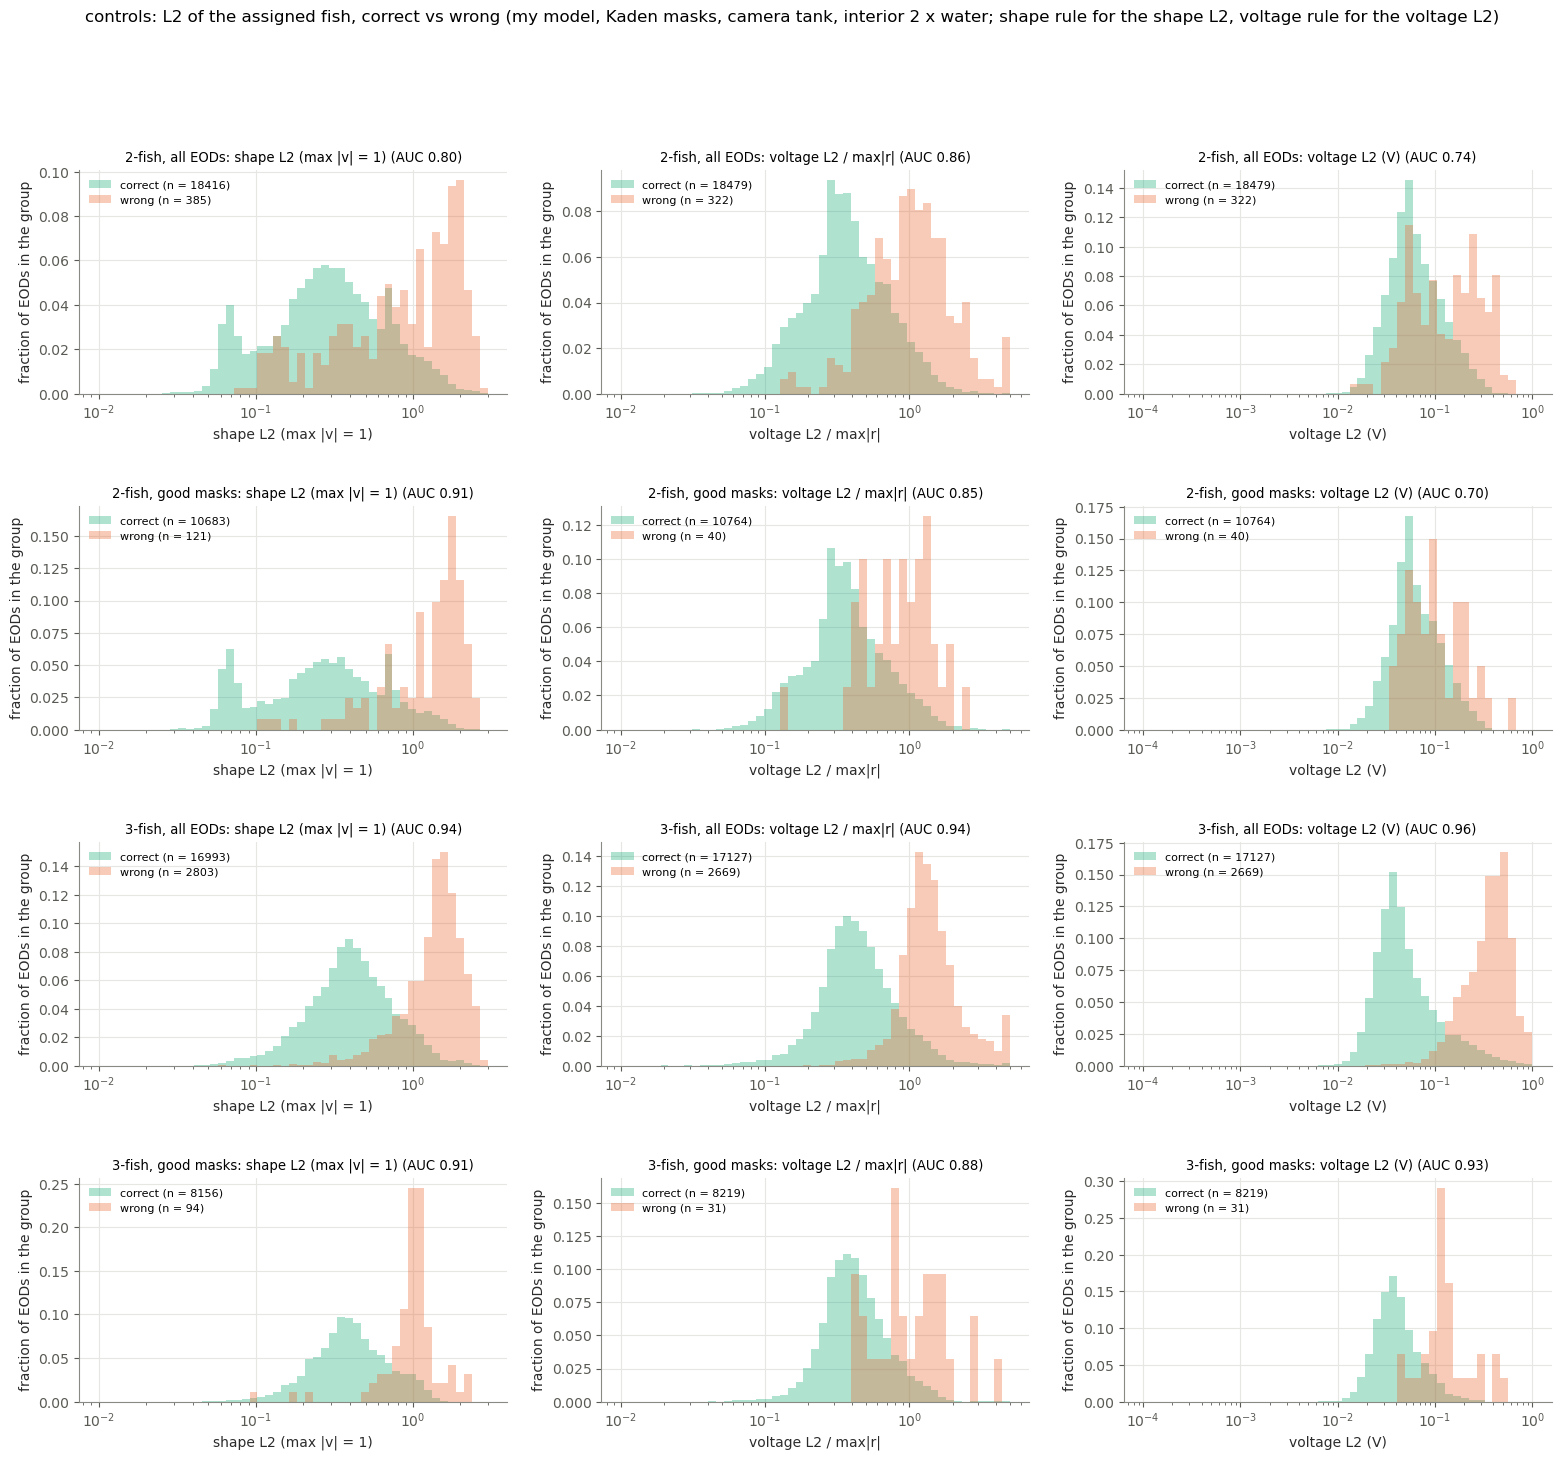

In [3]:
CTRL = {'2-fish': dict(n=2, emitter=1), '3-fish': dict(n=3, emitter=0)}
VERSION = 'N150_tank_int2_none'
res, stats = {}, []
for name, c in CTRL.items():
    base = f'results/eod_assignment_{c["n"]}_fish_silent/with_Kaden_tracking'
    T = pd.read_csv(f'{base}/{VERSION}/eod_assignment_shape.csv'); nf, em = c['n'], c['emitter']
    R = T[[f'r_raw_p{q}' for q in range(1, 11)]].to_numpy()
    U = np.stack([T[[f'u{f}_raw_p{q}' for q in range(1, 11)]].to_numpy() for f in range(nf)], 1)          # (n, fish, 10) raw sign
    DS = np.stack([T[f'd{f}'].to_numpy() for f in range(nf)], 1)
    good = T.Frame.isin(set(pd.read_csv(f'{base}/mask_qc_good_frames.csv').frame)).to_numpy()
    z = np.load(f'{base}/mask_midlines_by_frame_newest.npz', allow_pickle=True); gi = {int(k): i for i, k in enumerate(z['frames'])}
    MT = z['midlines_tank']                                                                   # load once (npz members decompress on every access)
    EL = pd.read_csv(f'data/electrodes/electrode_locations_updated_{nf}-fish.csv').sort_values('pair')
    plus = np.array([(r.x1, r.y1) if str(r.pol1).strip() == '+' else (r.x2, r.y2) for _, r in EL.iterrows()], float)
    minus = np.array([(r.x2, r.y2) if str(r.pol1).strip() == '+' else (r.x1, r.y1) for _, r in EL.iterrows()], float)
    pole = np.zeros((len(T), nf, 10), int)
    for i, k in enumerate(T.Frame.to_numpy()):
        if int(k) not in gi: continue
        M = MT[gi[int(k)]]
        for f in range(nf):
            if not np.isfinite(M[f]).all(): continue
            xy = M[f][:, ::-1] * (P - 1)
            pole[i, f] = (np.linalg.norm(xy[:, None] - minus[None], axis=-1).min(0) < np.linalg.norm(xy[:, None] - plus[None], axis=-1).min(0)).astype(int)
    # median factors from the true emitter's good-mask EODs, 2 loudest pairs
    Ue = MODEL_SIGN * U[:, em]; ii = np.arange(len(T)); ratios = []
    for i in np.flatnonzero(good & np.isfinite(Ue).all(1)):
        for p in np.argsort(-np.abs(R[i]))[:2]:
            if np.sign(R[i, p]) == np.sign(Ue[i, p]) and abs(Ue[i, p]) >= 0.05 * np.abs(Ue[i]).max():
                ratios.append((abs(R[i, p]) / abs(Ue[i, p]), p, pole[i, em, p]))
    ratios = np.array(ratios); a = np.median(ratios[:, 0]); E = np.ones((10, 2))
    for p in range(10):
        for s in range(2):
            k = (ratios[:, 1] == p) & (ratios[:, 2] == s)
            if k.any(): E[p, s] = np.median(ratios[k, 0] / a)
    pred = a * E[np.arange(10)[None, None, :], pole] * MODEL_SIGN * U
    DV = np.linalg.norm(R[:, None] - pred, axis=2)
    pick_v = np.where(np.isfinite(DV).any(1), np.nanargmin(np.where(np.isfinite(DV), DV, np.inf), 1), -1)
    pick_s = T.pick.to_numpy()
    X = {'shape': (DS[ii, np.clip(pick_s, 0, None)], pick_s == em), 'rel': (DV[ii, np.clip(pick_v, 0, None)] / np.abs(R).max(1), pick_v == em),
         'volt': (DV[ii, np.clip(pick_v, 0, None)], pick_v == em)}
    valid = {'shape': pick_s >= 0, 'rel': pick_v >= 0, 'volt': pick_v >= 0}
    res[name] = (X, valid, good)
    for m, (xlab, _) in MEAS.items():
        x, ok = X[m]
        for sub, k in (('all EODs', valid[m]), ('good masks', valid[m] & good)):
            stats.append(dict(control=name, measure=xlab, subset=sub, n=int(k.sum()), accuracy=ok[k].mean() * 100, n_wrong=int((~ok & k).sum()),
                              median_correct=np.median(x[k & ok]), median_wrong=np.median(x[k & ~ok]) if (k & ~ok).any() else np.nan,
                              AUC_wrong_vs_correct=auc(x[k & ~ok], x[k & ok])))
    print(f'{name}: fish factor {a:.4f}; {len(ratios)} emitter ratios')
ST = pd.DataFrame(stats); ST.to_csv(f'{OUT}/l2_controls_correct_vs_wrong.csv', index=False); display(ST.round(3))

fig, axs = plt.subplots(4, 3, figsize=(19, 16), gridspec_kw=dict(hspace=0.5, wspace=0.22))
for r0, name in enumerate(CTRL):
    X, valid, good = res[name]
    for s_, (sub, gmask) in enumerate((('all EODs', None), ('good masks', good))):
        for c_, (m, (xlab, bins)) in enumerate(MEAS.items()):
            ax = axs[2 * r0 + s_, c_]; x, ok = X[m]; k = valid[m] if gmask is None else valid[m] & gmask
            hist(ax, x[k & ok], bins, OK_COL, f'correct (n = {(k & ok).sum()})')
            hist(ax, x[k & ~ok], bins, BAD_COL, f'wrong (n = {(k & ~ok).sum()})')
            a_ = ST[(ST.control == name) & (ST.measure == xlab) & (ST.subset == sub)].AUC_wrong_vs_correct.iloc[0]
            ax.set(xscale='log', ylim=(0, None), xlabel=xlab, ylabel='fraction of EODs in the group')
            ax.set_title(f'{name}, {sub}: {xlab} (AUC {a_:.2f})', fontsize=9.5)
            ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.suptitle(f'controls: L2 of the assigned fish, correct vs wrong (my model, Kaden masks, camera tank, interior 2 x water; '
             'shape rule for the shape L2, voltage rule for the voltage L2)', fontsize=12)
fig.savefig(f'{OUT}/l2_controls_correct_vs_wrong.png', dpi=100, bbox_inches='tight'); plt.show()

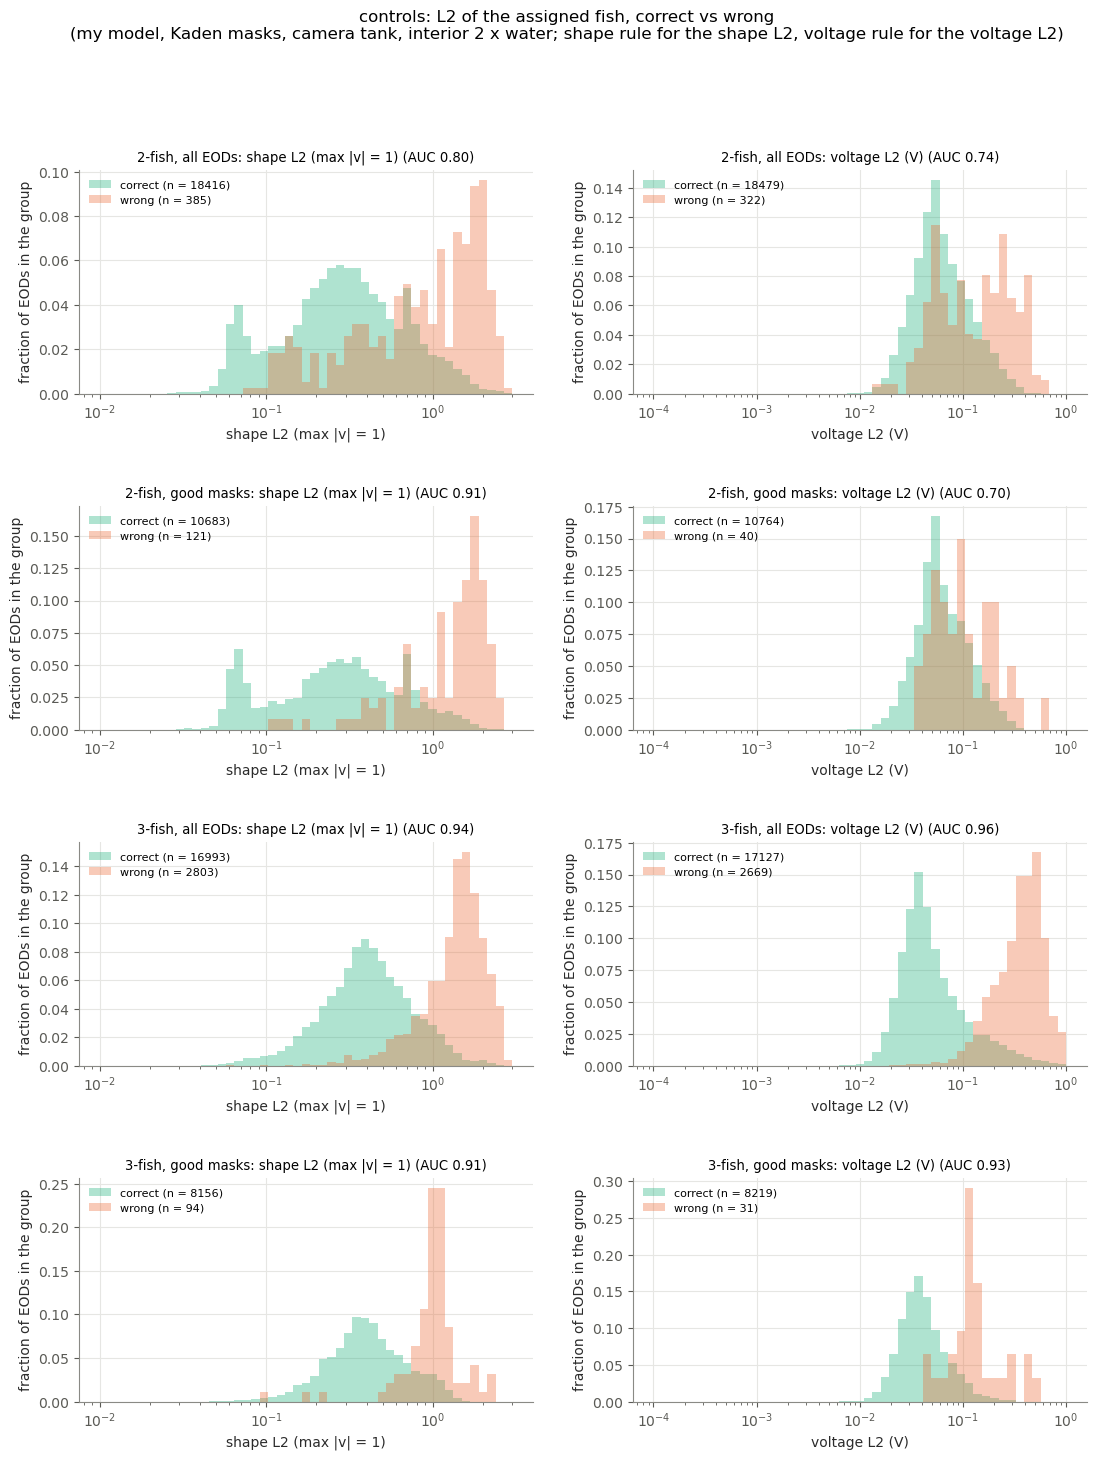

In [4]:
# the same figure with the shape L2 and the voltage L2 (V) only (no L2 / max|r| column)
M2 = {m: MEAS[m] for m in ('shape', 'volt')}
fig, axs = plt.subplots(4, 2, figsize=(13, 16), gridspec_kw=dict(hspace=0.5, wspace=0.22))
for r0, name in enumerate(CTRL):
    X, valid, good = res[name]
    for s_, (sub, gmask) in enumerate((('all EODs', None), ('good masks', good))):
        for c_, (m, (xlab, bins)) in enumerate(M2.items()):
            ax = axs[2 * r0 + s_, c_]; x, ok = X[m]; k = valid[m] if gmask is None else valid[m] & gmask
            hist(ax, x[k & ok], bins, OK_COL, f'correct (n = {(k & ok).sum()})')
            hist(ax, x[k & ~ok], bins, BAD_COL, f'wrong (n = {(k & ~ok).sum()})')
            a_ = ST[(ST.control == name) & (ST.measure == xlab) & (ST.subset == sub)].AUC_wrong_vs_correct.iloc[0]
            ax.set(xscale='log', ylim=(0, None), xlabel=xlab, ylabel='fraction of EODs in the group')
            ax.set_title(f'{name}, {sub}: {xlab} (AUC {a_:.2f})', fontsize=9.5)
            ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.suptitle('controls: L2 of the assigned fish, correct vs wrong\n(my model, Kaden masks, camera tank, interior 2 x water; '
             'shape rule for the shape L2, voltage rule for the voltage L2)', fontsize=12)
fig.savefig(f'{OUT}/l2_controls_correct_vs_wrong_shape_volt.png', dpi=100, bbox_inches='tight'); plt.show()

## Controls: L2 and errors against the emitter's heading, wall distance and electrode distance

For every EOD of the 2-/3-fish controls (shape rule, `N150_tank_int2_none`), from the **true emitter's** mask midline:
- **heading**: direction from the midline's middle point to the head tip, 0° = pointing right in the video (+x), 90° = up, 0–360°;
- **distance to the nearest wall**: smallest distance from any midline point to the tank outline (`tank_outline_updated_<n>-fish.csv`), cm;
- **distance to the nearest electrode pole**: smallest distance from any midline point to any of the 20 poles
  (`electrode_locations_updated_<n>-fish.csv`), cm, split by the sign of that pole;
- **distance to the nearest other fish**: smallest distance between the emitter's midline and any other fish's midline (every 5th
  point), cm; EODs where no other fish has a midline are left out of this row.

Left of each pair: the shape L2 of the assigned fish for correct (green) and wrong (orange) EODs, with the median per bin. Right:
the fraction of EODs assigned wrongly per bin (solid: all EODs; dashed: good-mask EODs). 15.2 px/cm.

2-fish: 18801 EODs with an emitter midline, 385 wrong


3-fish: 18508 EODs with an emitter midline, 1515 wrong


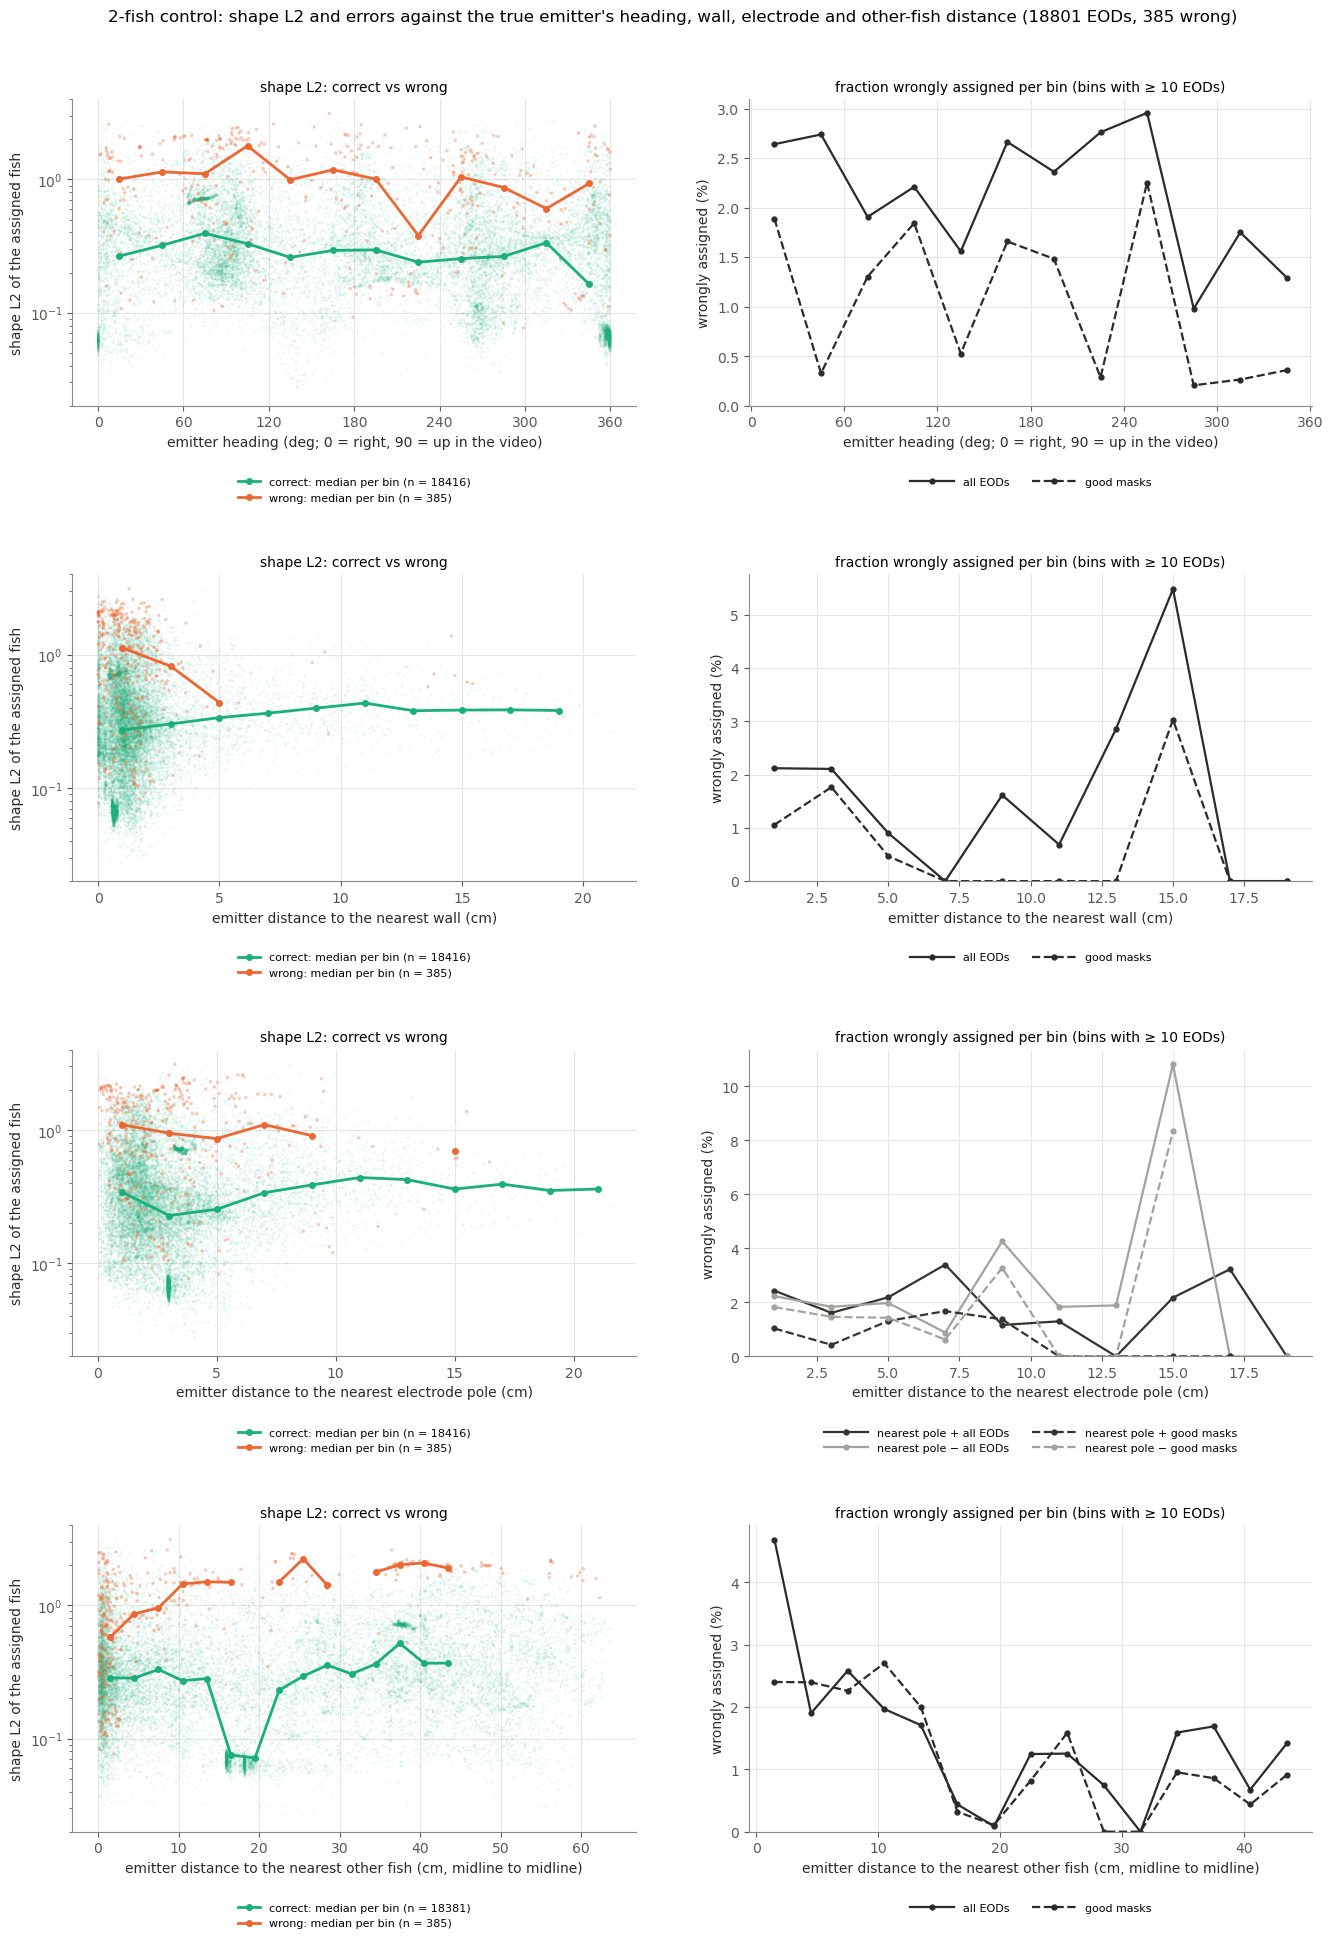

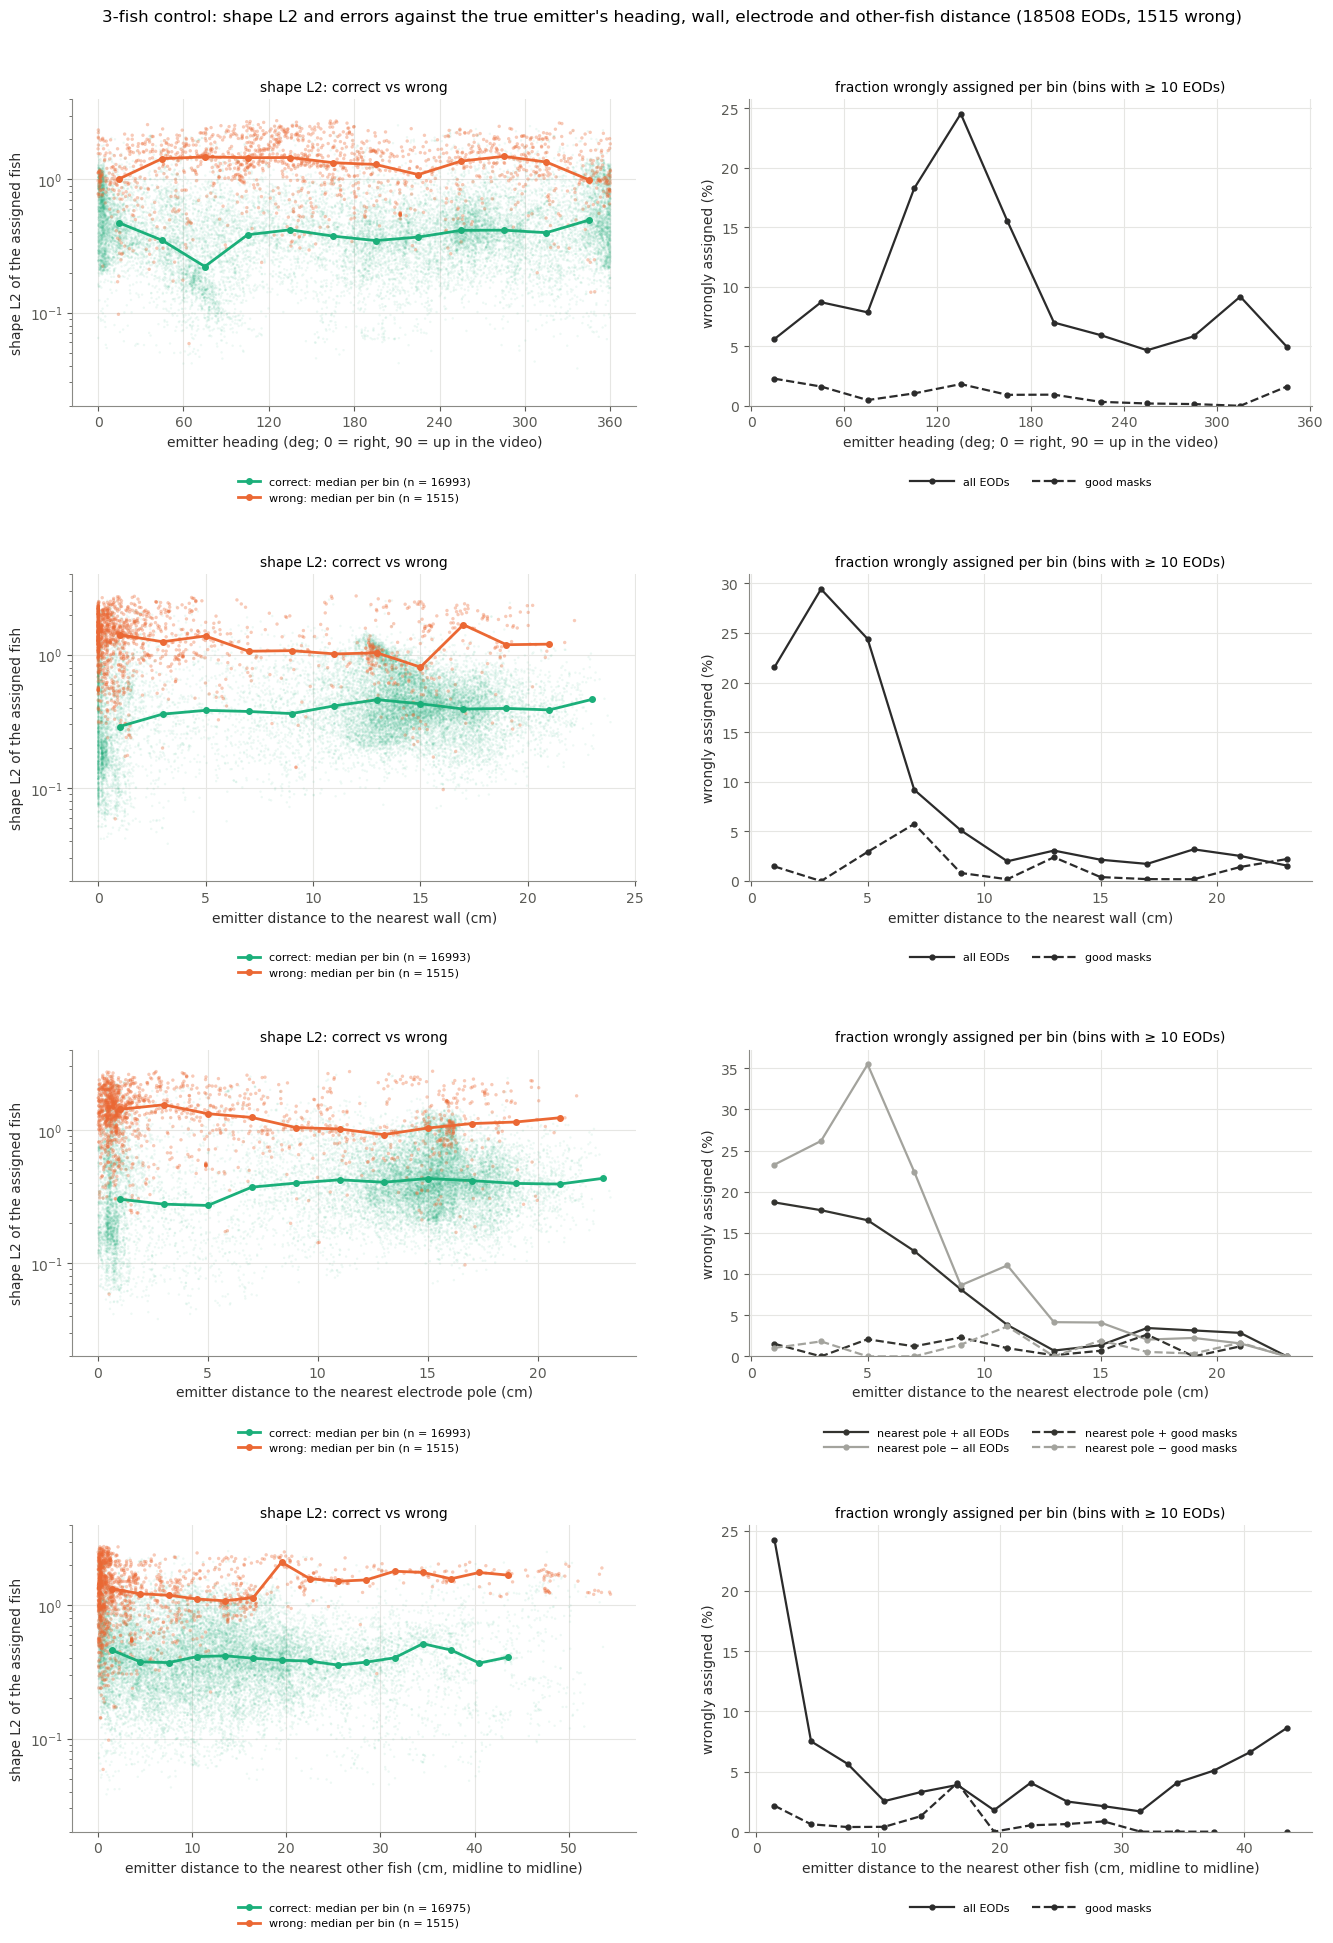

In [5]:
PXCM = 912 / 60
def seg_dist(pts, a, b):
    '''distance from points (n, 2) to segment a-b.'''
    ab = b - a; t = np.clip(((pts - a) @ ab) / (ab @ ab), 0, 1); return np.linalg.norm(pts - (a + t[:, None] * ab), axis=1)
GEO = {}
for name, c in CTRL.items():
    base = f'results/eod_assignment_{c["n"]}_fish_silent/with_Kaden_tracking'; nf, em = c['n'], c['emitter']
    T = pd.read_csv(f'{base}/{VERSION}/eod_assignment_shape.csv')
    z = np.load(f'{base}/mask_midlines_by_frame_newest.npz', allow_pickle=True); MT = z['midlines_tank']; gi = {int(k): i for i, k in enumerate(z['frames'])}
    V = pd.read_csv(f'data/electrodes/tank_outline_updated_{nf}-fish.csv')[['x', 'y']].to_numpy(float); V2 = np.vstack([V, V[:1]])
    EL = pd.read_csv(f'data/electrodes/electrode_locations_updated_{nf}-fish.csv')
    poles = np.array([(r[f'x{k}'], r[f'y{k}']) for _, r in EL.iterrows() for k in (1, 2)], float)
    sign = np.array([str(r[f'pol{k}']).strip() for _, r in EL.iterrows() for k in (1, 2)])
    good = T.Frame.isin(set(pd.read_csv(f'{base}/mask_qc_good_frames.csv').frame)).to_numpy()
    rows = []
    for i, (k, pk) in enumerate(zip(T.Frame.to_numpy(), T.pick.to_numpy())):
        if int(k) not in gi or pk < 0: continue
        m = MT[gi[int(k)], em]
        if not np.isfinite(m).all(): continue
        xy = m[:, ::-1] * (912 - 1)                                                             # (101, x/y) px
        hd = xy[-1] - xy[50]; ang = np.degrees(np.arctan2(-hd[1], hd[0])) % 360
        dwall = min(seg_dist(xy, V2[j], V2[j + 1]).min() for j in range(len(V)))
        dp = np.linalg.norm(xy[:, None] - poles[None], axis=-1).min(0); jn = int(dp.argmin())
        others = [MT[gi[int(k)], h][::5, ::-1] * (912 - 1) for h in range(nf) if h != em and np.isfinite(MT[gi[int(k)], h]).all()]
        dfish = min(np.linalg.norm(xy[::5, None] - o[None], axis=-1).min() for o in others) / PXCM if others else np.nan
        rows.append(dict(i=i, heading=ang, d_wall=dwall / PXCM, d_pole=dp[jn] / PXCM, pole_sign=sign[jn], d_fish=dfish,
                         l2=T[f'd{pk}'].iloc[i], correct=pk == em, good=good[i]))
    GEO[name] = pd.DataFrame(rows)
    G = GEO[name]; print(f'{name}: {len(G)} EODs with an emitter midline, {(~G.correct).sum()} wrong')

def err_and_l2(axl, axe, G, x, bins, xlab, groups=None):
    for ok, col, lab in ((True, OK_COL, 'correct'), (False, BAD_COL, 'wrong')):
        g = G[G.correct == ok]
        axl.scatter(g[x], g.l2, s=3 if ok else 6, alpha=0.08 if ok else 0.35, color=col, edgecolor='none')
        b = np.digitize(g[x], bins) - 1; c = (bins[:-1] + bins[1:]) / 2
        med = [np.median(g.l2[b == j]) if (b == j).sum() >= 5 else np.nan for j in range(len(c))]
        axl.plot(c, med, '-o', color=col, ms=4, lw=2, label=f'{lab}: median per bin (n = {len(g)})')
    axl.set(yscale='log', ylim=(0.02, 4), xlabel=xlab, ylabel='shape L2 of the assigned fish'); axl.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    for sub, ls in (('all EODs', '-'), ('good masks', '--')):
        g = G if sub == 'all EODs' else G[G.good]
        for gname, gg, col in (groups or [('', g, '#2b2b2b')]):
            if groups: gg = gg if sub == 'all EODs' else gg[gg.good]
            b = np.digitize(gg[x], bins) - 1; c = (bins[:-1] + bins[1:]) / 2
            n = np.array([(b == j).sum() for j in range(len(c))]); w = np.array([(~gg.correct[b == j]).sum() for j in range(len(c))])
            fr = np.where(n >= 10, w / np.maximum(n, 1) * 100, np.nan)
            axe.plot(c, fr, ls, color=col, marker='o', ms=3.5, lw=1.6, label=f'{gname}{" " if gname else ""}{sub}')
    axe.set(ylim=(0, None), xlabel=xlab, ylabel='wrongly assigned (%)'); axe.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2, handlelength=4)

for name in CTRL:
    G = GEO[name]
    fig, axs = plt.subplots(4, 2, figsize=(16, 22.5), gridspec_kw=dict(hspace=0.55, wspace=0.2))
    err_and_l2(axs[0, 0], axs[0, 1], G, 'heading', np.arange(0, 361, 30), "emitter heading (deg; 0 = right, 90 = up in the video)")
    err_and_l2(axs[1, 0], axs[1, 1], G, 'd_wall', np.arange(0, 32, 2), 'emitter distance to the nearest wall (cm)')
    grp = [('nearest pole +', G[G.pole_sign == '+'], '#33332F'), ('nearest pole −', G[G.pole_sign == '-'], '#A3A39D')]
    err_and_l2(axs[2, 0], axs[2, 1], G, 'd_pole', np.arange(0, 32, 2), 'emitter distance to the nearest electrode pole (cm)', groups=grp)
    Gf = G[np.isfinite(G.d_fish)]
    err_and_l2(axs[3, 0], axs[3, 1], Gf, 'd_fish', np.arange(0, 46, 3), 'emitter distance to the nearest other fish (cm, midline to midline)')
    for ax in axs[:, 0]: ax.set_title('shape L2: correct vs wrong', fontsize=10)
    for ax in axs[:, 1]: ax.set_title('fraction wrongly assigned per bin (bins with ≥ 10 EODs)', fontsize=10)
    axs[0, 0].set_xticks(range(0, 361, 60)); axs[0, 1].set_xticks(range(0, 361, 60))
    fig.suptitle(f'{name} control: shape L2 and errors against the true emitter\'s heading, wall, electrode and other-fish distance '
                 f'({len(G)} EODs, {(~G.correct).sum()} wrong)', fontsize=12, y=0.92)
    fig.savefig(f'{OUT}/l2_vs_geometry_{name}.png', dpi=95, bbox_inches='tight'); plt.show()

### Heading modulo 90°

The tank is close to a square, so a heading and the same heading turned by 90°, 180° or 270° see the walls the same way (up to the
electrode layout). Here the emitter's heading is folded to 0–90° (heading mod 90): 0° = parallel to a wall, 45° = diagonal.

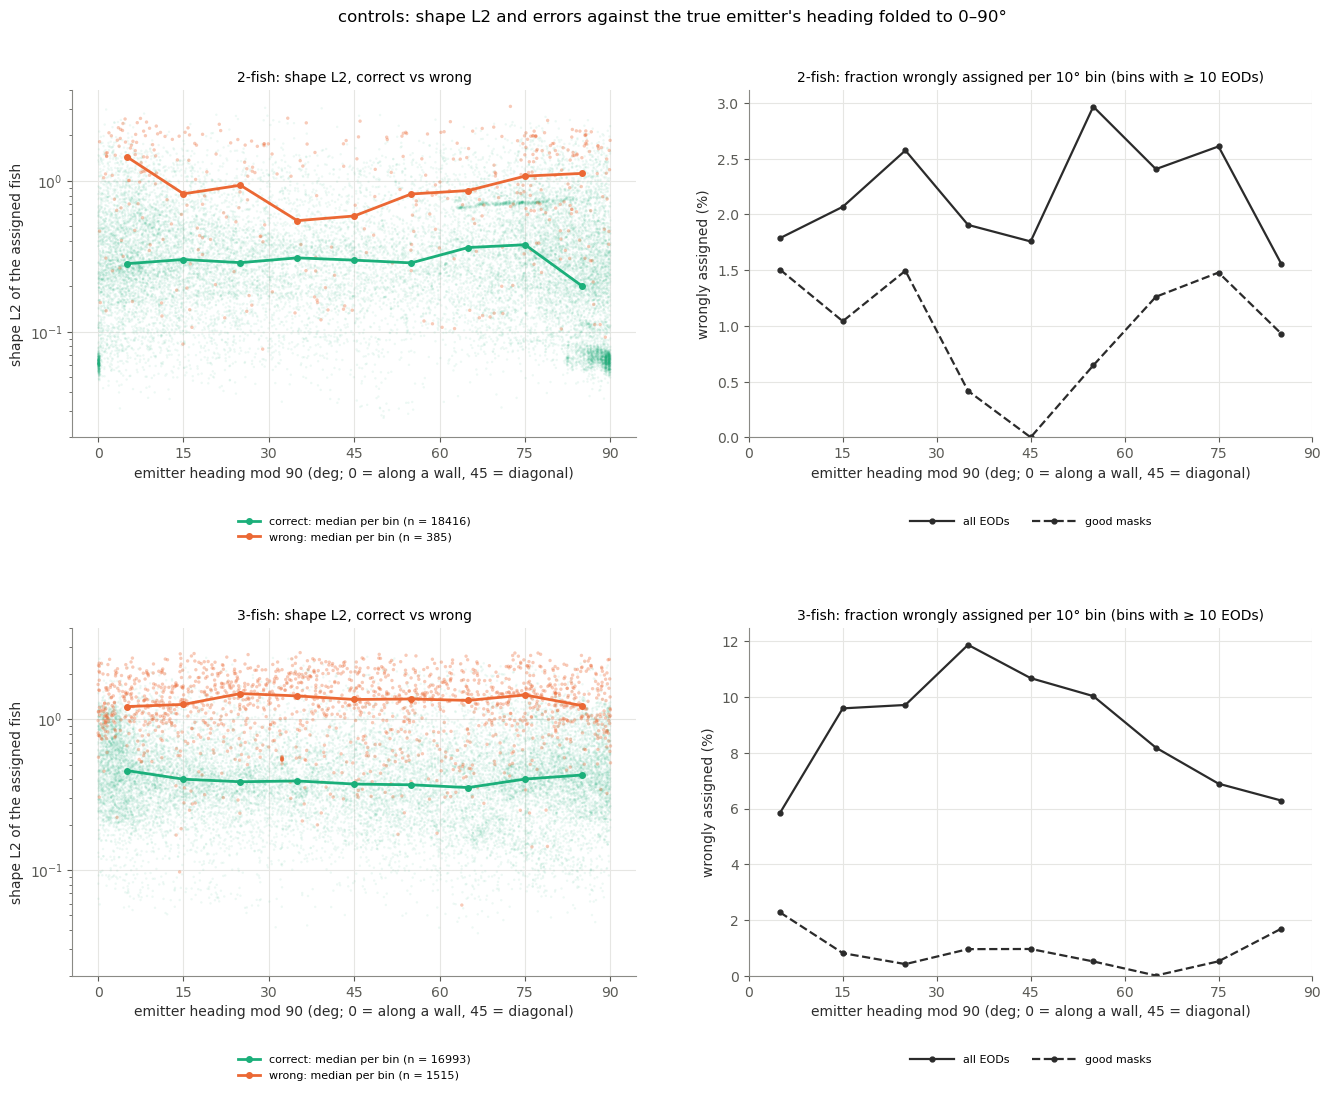

In [6]:
fig, axs = plt.subplots(2, 2, figsize=(16, 11.5), gridspec_kw=dict(hspace=0.55, wspace=0.2))
for r_, name in enumerate(CTRL):
    G = GEO[name].assign(heading90=GEO[name].heading % 90)
    err_and_l2(axs[r_, 0], axs[r_, 1], G, 'heading90', np.arange(0, 91, 10), 'emitter heading mod 90 (deg; 0 = along a wall, 45 = diagonal)')
    axs[r_, 0].set_title(f'{name}: shape L2, correct vs wrong', fontsize=10)
    axs[r_, 1].set_title(f'{name}: fraction wrongly assigned per 10° bin (bins with ≥ 10 EODs)', fontsize=10)
    for ax in axs[r_]: ax.set_xticks(range(0, 91, 15))
fig.suptitle('controls: shape L2 and errors against the true emitter\'s heading folded to 0–90°', fontsize=12, y=0.95)
fig.savefig(f'{OUT}/l2_vs_heading_mod90_controls.png', dpi=95, bbox_inches='tight'); plt.show()

### Where the emitter was: correct (grey) and wrong (red) EODs

The true emitter's mask midline at every EOD, drawn on the tank (outline and electrodes of that control, + filled, − open): correct
EODs in grey (thin, transparent; drawn first), wrongly assigned EODs in red on top. Left: all EODs; right: good-mask EODs only.

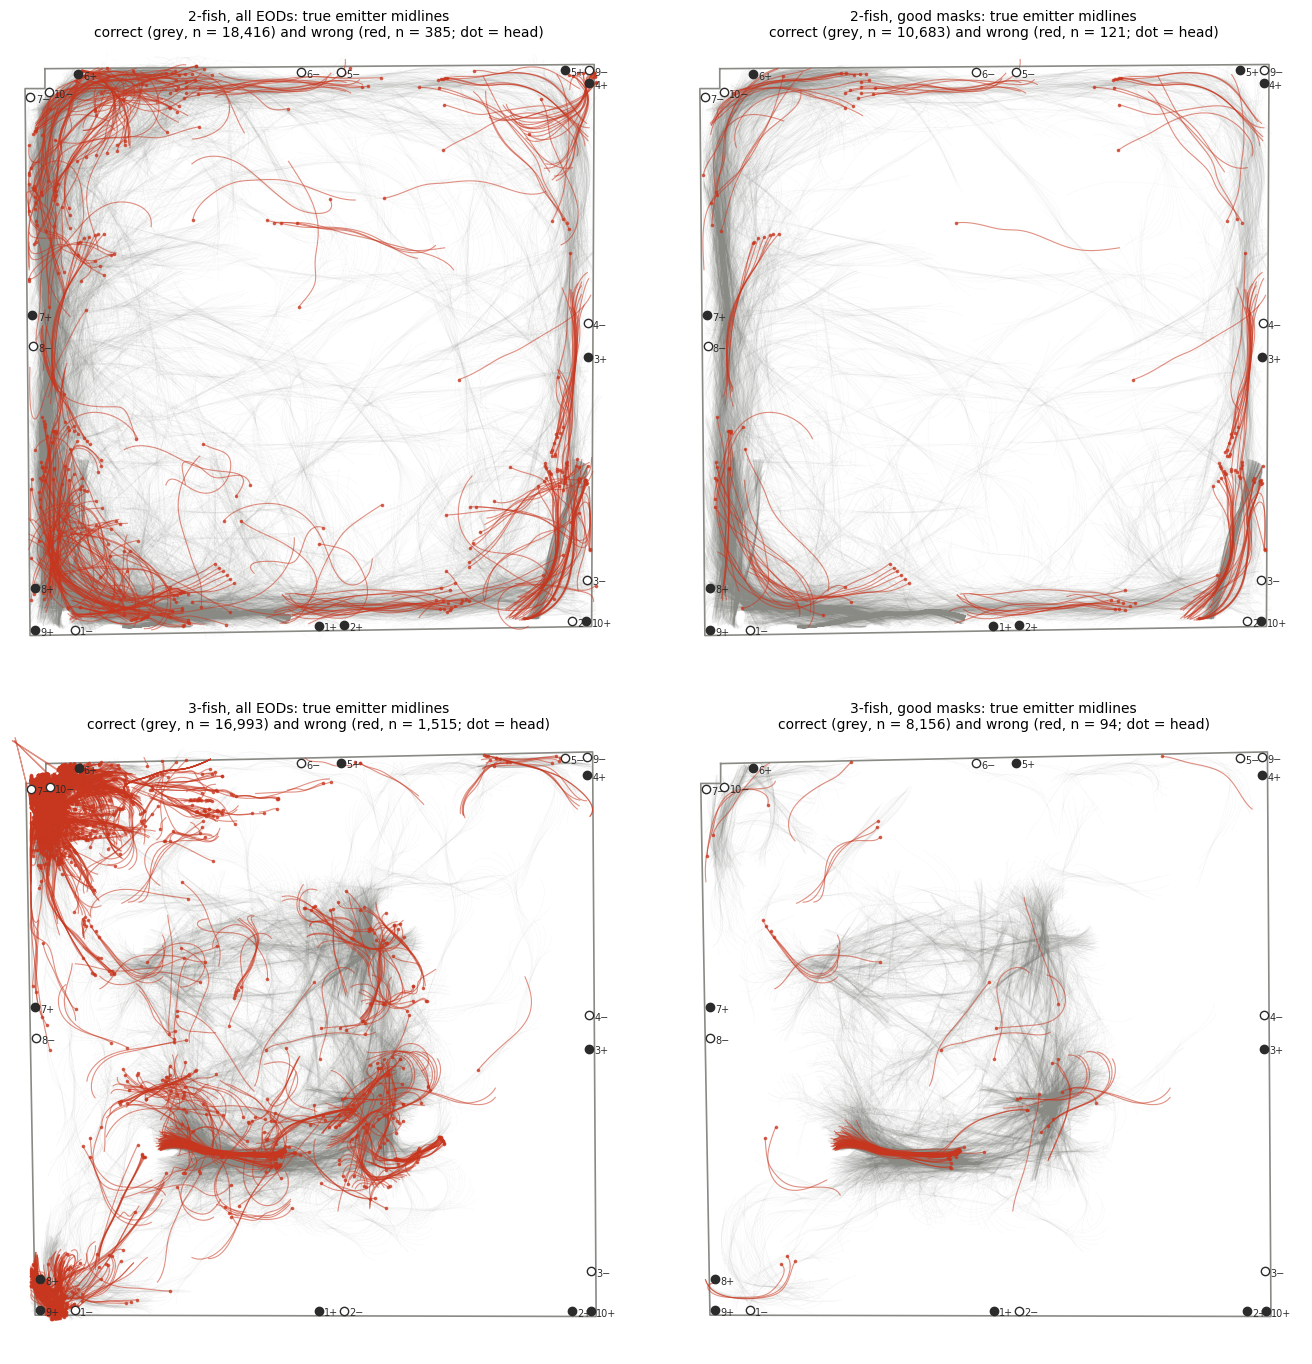

In [7]:
def draw_tank(ax, nf):
    V = pd.read_csv(f'data/electrodes/tank_outline_updated_{nf}-fish.csv')[['x', 'y']].to_numpy(float)
    ax.plot(*np.vstack([V, V[:1]]).T, color='#8a8a85', lw=1.2)
    for _, r in pd.read_csv(f'data/electrodes/electrode_locations_updated_{nf}-fish.csv').iterrows():
        for k in (1, 2):
            pos = str(r[f'pol{k}']).strip() == '+'
            ax.plot(r[f'x{k}'], r[f'y{k}'], 'o', ms=6, mfc='#2b2b2b' if pos else 'white', mec='#2b2b2b', mew=1, zorder=5)
            ax.text(r[f'x{k}'] + 8, r[f'y{k}'] + 8, f"{int(r.pair)}{'+' if pos else '−'}", fontsize=7, color='#2b2b2b', zorder=5)
    ax.set(xlim=(-10, 922), ylim=(922, -10), aspect='equal', xticks=[], yticks=[]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)

from matplotlib.collections import LineCollection
fig, axs = plt.subplots(2, 2, figsize=(17, 17), gridspec_kw=dict(hspace=0.12, wspace=0.05))
for r_, (name, c) in enumerate(CTRL.items()):
    base = f'results/eod_assignment_{c["n"]}_fish_silent/with_Kaden_tracking'; nf, em = c['n'], c['emitter']
    T = pd.read_csv(f'{base}/{VERSION}/eod_assignment_shape.csv')
    z = np.load(f'{base}/mask_midlines_by_frame_newest.npz', allow_pickle=True); MT = z['midlines_tank']; gi = {int(k): i for i, k in enumerate(z['frames'])}
    G = GEO[name]
    lines = {i: MT[gi[int(T.Frame.iloc[i])], em][:, ::-1] * (912 - 1) for i in G.i}
    for c_, sub in enumerate(('all EODs', 'good masks')):
        ax = axs[r_, c_]; draw_tank(ax, nf); g = G if sub == 'all EODs' else G[G.good]
        ok, bad = g[g.correct], g[~g.correct]
        ax.add_collection(LineCollection([lines[i] for i in ok.i], colors='#8a8a85', linewidths=0.4, alpha=0.06, zorder=1))
        ax.add_collection(LineCollection([lines[i] for i in bad.i], colors='#C8361E', linewidths=0.8, alpha=0.55, zorder=3))
        for i in bad.i: ax.plot(*lines[i][-1], 'o', ms=1.6, color='#C8361E', alpha=0.7, zorder=4)
        ax.set_title(f'{name}, {sub}: true emitter midlines\ncorrect (grey, n = {len(ok):,}) and wrong (red, n = {len(bad):,}; dot = head)', fontsize=10)
fig.savefig(f'{OUT}/emitter_midlines_correct_vs_wrong_controls.png', dpi=100, bbox_inches='tight'); plt.show()